# Exploração dos Dados

&nbsp;&nbsp;&nbsp;&nbsp; Nesta etapa, foi realizada uma análise exploratória detalhada dos dados, com o objetivo de compreender as principais características das variáveis e suas relações. O processo seguiu as seguintes etapas:

### Importação de Bibliotecas Necessárias

&nbsp;&nbsp;&nbsp;&nbsp; No código abaixo, são importadas as principais bibliotecas utilizadas para o tratamento de dados e a criação de gráficos, como Numpy, Pandas, Matplotlib, Seaborn e Scikit-Learn.

In [1]:
# Importar pacotes
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder,  MinMaxScaler, LabelEncoder
from sklearn.compose import ColumnTransformer

### Importação das Planilhas de Dados

&nbsp;&nbsp;&nbsp;&nbsp; O código abaixo importa as planilhas disponibilizadas pela empresa parceira Finnet.

In [2]:
# Carregar os arquivos CSV


# Carregamento em amostras para economia de memória e testes

df_gf = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GF.csv", sep="\t", header=0, engine="python").sample(n=5000, random_state=42)
df_gl = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GL.csv", sep="\t", header=0, engine="python").sample(n=5000, random_state=42)
df_gm = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GM.csv", sep="\t", header=0, engine="python").sample(n=5000, random_state=42)
df_gp = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GP.csv", sep="\t", header=0, engine="python").sample(n=5000, random_state=42)
df_gt = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GT.csv", sep="\t", header=0, engine="python").sample(n=5000, random_state=42)
df_gv = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GV.csv", sep="\t", header=0, engine="python").sample(n=5000, random_state=42)
df_gw = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GW.csv", sep="\t", header=0, engine="python").sample(n=5000, random_state=42)

# Após carregar, conversão de floats para float32 para economizar memória também

for df in [df_gf, df_gl, df_gm, df_gp, df_gt, df_gv, df_gw]:
    for col in df.select_dtypes(include="float64").columns:
        df[col] = df[col].astype("float32")


 ### Divisão de Colunas em Múltiplas Colunas

&nbsp;&nbsp;&nbsp;&nbsp; Após importar os arquivos CSV, todas as informações vieram concentradas em uma única coluna. Para resolver isso, foi criada uma função que divide corretamente os valores em múltiplas colunas, utiliza a primeira linha como cabeçalho e retorna o DataFrame ajustado. Essa função foi aplicada em todos os Dataframes.

In [3]:
# Função para a divisão das colunas

def dividir_colunas(df):

    # Verifica se o DataFrame tem apenas uma coluna.

    if df.shape[1] == 1:

        # Divide a única coluna em múltiplas colunas.

        dados = df.iloc[:, 0].str.split('\t', expand=True)

        # Usa a primeira linha como nomes das colunas.

        dados.columns = dados.iloc[0]

        # Remove a primeira linha por ter virado cabeçalho.

        dados = dados.drop(index=0).reset_index(drop=True)
        return dados
    else:

        return df

df_gf = dividir_colunas(df_gf)
df_gl = dividir_colunas(df_gl)
df_gm = dividir_colunas(df_gm)
df_gp = dividir_colunas(df_gp)
df_gt = dividir_colunas(df_gt)
df_gv = dividir_colunas(df_gv)
df_gw = dividir_colunas(df_gw)

### Conversão de Tipos de Dados


&nbsp;&nbsp;&nbsp;&nbsp; Esse código é responsável por padronizar os tipos de dados das colunas de diferentes DataFrames após a importação. Primeiro, ele organiza as colunas em quatro grupos: numéricas, categóricas, de datas e de texto. Em seguida, a função converter_tipos percorre cada grupo e faz os ajustes necessários. Para as colunas numéricas, substitui valores inválidos representados por \N por NaN e converte os dados para tipo numérico. Para as colunas categóricas, altera o tipo para category, o que facilita análises e economiza memória. Já nas colunas de datas, também substitui \N por NaN e converte para o formato datetime, permitindo operações temporais como filtragem e cálculos.

In [4]:
# Divisão de tipos

colunas_numericas = ['multa','id_grupo', 'id_pagador', 'id_beneficiario', 'Numero_do_boleto', 'vl_boleto', 'vl_pagto', 'juros']
colunas_categoricas = ['tipo_multa', 'status_boleto', 'pagador_cep', 'banco', 'tipo_juros', 'pagador_cidade']
colunas_data = ['data_inclusao', 'data_vencto', 'dt_pagto', 'pagador_dt_ultimo_acesso ']
colunas_texto = [ 'pagador_cnpjcpf', 'pagador_inscricao_hash']

# Função para converter em um DataFrame

def converter_tipos(df):

    # Converte colunas numéricas para tipo numérico, formatando '\N' como NaN

    for col in colunas_numericas:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col].replace('\\N', np.nan), errors='coerce')

    # Converte colunas categóricas para category

    for col in colunas_categoricas:
        if col in df.columns:
            df[col] = df[col].astype('category')

    # Converte colunas de data para tipo datetime, formatando '\N' como NaN

    for col in colunas_data:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col].replace('\\N', np.nan), errors='coerce')

# Aplica a função de conversão de tipos para cada DataFrame

for df in [df_gf, df_gl, df_gm, df_gp, df_gt, df_gv, df_gw]:
    converter_tipos(df)

C:\Users\Inteli\AppData\Local\Temp\ipykernel_64004\201677261.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = pd.to_numeric(df[col].replace('\\N', np.nan), errors='coerce')
C:\Users\Inteli\AppData\Local\Temp\ipykernel_64004\201677261.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = pd.to_numeric(df[col].replace('\\N', np.nan), errors='coerce')


## Tratamento de Valores Ausentes

O código abaixo passa por todos os dataframes e remove valores ausentes das colunas 'vl_pagto', 'multa' e 'qtd_acessos_pagador' e substitui esses valores por 0.

In [5]:
# Colunas para remoção considerando que tem muitos valores ausentes

# colunas_para_remover = ['tipo_multa', 'multa']

for df in [df_gf, df_gl, df_gm, df_gp, df_gt, df_gv, df_gw]:

    # df.drop(columns=[c for c in colunas_para_remover if c in df.columns], inplace=True)

    # Substitui valores ausentes em colunas numéricas por 0

    colunas_ausentes = ['vl_pagto', 'multa', 'qtd_acessos_pagador']

    for coluna in colunas_ausentes:
        if coluna in df.columns:
            df[coluna] = df[coluna].fillna(0)

    # Trata valores ausentes em pagador_cidade

    if 'pagador_cidade' in df.columns:
        df['pagador_cidade'] = df['pagador_cidade'].cat.add_categories('Desconhecido')
        df['pagador_cidade'] = df['pagador_cidade'].fillna('Desconhecido')


## Identificação e Tratamento de Outliers


Esse código percorre várias tabelas e, nas colunas numéricas, identifica outliers pelo intervalo interquartil (IQR) e os substitui pelos limites mínimo e máximo aceitáveis, ajustando valores extremos sem excluir dados.

In [6]:
# Verificação em quartis

for df in [df_gf, df_gl, df_gm, df_gp, df_gt, df_gv, df_gw]:
    for col in colunas_numericas:
        if col in df.columns:

            # Calcula o primeiro quartil (Q1)

            Q1 = df[col].quantile(0.25)

            # Calcula o terceiro quartil (Q3)

            Q3 = df[col].quantile(0.75)

            # Calcula o Intervalo Interquartil (IQR)

            IQR = Q3 - Q1

            # Define os limites inferior e superior para identificar os outliers

            lim_inf = Q1 - 1.5 * IQR
            lim_sup = Q3 + 1.5 * IQR

            # Substitui valores fora dos limites pelos próprios limites

            df[col] = np.clip(df[col], lim_inf, lim_sup)

In [7]:
print(df_gf.columns.tolist())


['id_grupo', 'id_beneficiario', 'Numero_do_boleto', 'data_inclusao', 'status_boleto', 'data_vencto', 'vl_boleto', 'dt_pagto', 'vl_pagto', 'banco', 'id_pagador', 'pagador_cep', 'pagador_cidade', 'qtd_acessos_pagador', 'pagador_dt_ultimo_acesso', 'pagador_cnpjcpf', 'pagador_inscricao_hash', 'valor_abatimento', 'tipo_juros', 'juros', 'tipo_multa', 'multa']


## Pré-processamento (Normalização e Codificação)

O código cria uma função que tem a finalidade de pré-processar os dados, convertendo colunas numéricas para tipos adequados, normalizando valores quando necessário. Além disso, transforma variáveis categóricas como 'pagador_cidade', 'status_boleto', 'tipo_juros', 'tipo_multa', 'pagador_cep' e 'banco' em números com LabelEncoder, que associa cada categoria a um número correspondente, assim preparando o DataFrame para uso em modelos de Machine Learning.

In [8]:
# Pré-processamento (One-Hot e Normalização no escopo de 0 a 10000)
colunas_numericas = ['id_grupo','id_pagador','id_beneficiario','Numero_do_boleto',
                     'vl_boleto','vl_pagto','juros','multa','valor_abatimento','qtd_acessos_pagador']
colunas_categoricas = ['status_boleto','banco','pagador_cidade','tipo_juros','tipo_multa']
colunas_data = ['data_inclusao','data_vencto','dt_pagto','pagador_dt_ultimo_acesso']
colunas_texto = ['pagador_cep','pagador_cnpjcpf','pagador_inscricao_hash']

colunas_nao_normalizar = ['id_grupo','id_beneficiario','Numero_do_boleto','id_pagador',
                          'pagador_cep','data_inclusao','data_vencto','dt_pagto','pagador_dt_ultimo_acesso']

# Criando um codificador para cada variável categórica

Banco_encoder = LabelEncoder()
Cidade_Pagador_encoder = LabelEncoder()
Status_boleto_encoder = LabelEncoder()
Juros_encoder = LabelEncoder()
cep_encoder = LabelEncoder()
Multa_encoder = LabelEncoder()

def preprocessar(df):
    df_proc = df

    # Normalização numérica

    num_candidatas = [c for c in colunas_numericas if c in df_proc.columns]
    num_para_normalizar = [c for c in num_candidatas if c not in colunas_nao_normalizar]

    if num_para_normalizar:
        X_num = df_proc[num_para_normalizar].copy()

        # Substitui '\N' por NaN

        X_num = X_num.replace('\\N', np.nan)

        # Converte para numérico

        X_num = X_num.apply(pd.to_numeric, errors='coerce')

        scaler = MinMaxScaler(feature_range=(0, 10000))
        arr_norm = scaler.fit_transform(X_num)
        df_norm = pd.DataFrame(arr_norm, columns=[f'{c}_norm' for c in num_para_normalizar], index=df_proc.index)
        for c in df_norm.columns:
            df_norm[c] = df_norm[c].astype('float32')
        df_proc = pd.concat([df_proc, df_norm], axis=1)
    # Conversão float64 pra float32

    for c in df_proc.select_dtypes(include='float64').columns:
        df_proc[c] = df_proc[c].astype('float32')

    # Usando LabelEncoder para variáveis categóricas

    Banco_encoder.fit(df_proc['banco'])
    df_proc['banco'] = Banco_encoder.transform(df_proc['banco'])
    
    Cidade_Pagador_encoder.fit(df_proc['pagador_cidade'])
    df_proc['pagador_cidade'] = Cidade_Pagador_encoder.transform(df_proc['pagador_cidade'])

    Status_boleto_encoder.fit(df_proc['status_boleto'])
    df_proc['status_boleto'] = Status_boleto_encoder.transform(df_proc['status_boleto'])

    Juros_encoder.fit(df_proc['tipo_juros'])
    df_proc['tipo_juros'] = Juros_encoder.transform(df_proc['tipo_juros'])

    Multa_encoder.fit(df_proc['tipo_multa'])
    df_proc['tipo_multa'] = Multa_encoder.transform(df_proc['tipo_multa'])

    cep_encoder.fit(df_proc['pagador_cep'])
    df_proc['pagador_cep'] = cep_encoder.transform(df_proc['pagador_cep'])


    return df_proc

O código abaixo aplica a função de pré-processamento a cada DataFrame.

In [9]:

df_gf_pre = preprocessar(df_gf)
df_gl_pre = preprocessar(df_gl)
df_gm_pre = preprocessar(df_gm)
df_gp_pre = preprocessar(df_gp)
df_gt_pre = preprocessar(df_gt)
df_gv_pre = preprocessar(df_gv)
df_gw_pre = preprocessar(df_gw)

C:\Users\Inteli\AppData\Local\Temp\ipykernel_64004\2999638011.py:33: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_num = X_num.replace('\\N', np.nan)
c:\Users\Inteli\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\_array_api.py:686: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmin(X, axis=axis))
c:\Users\Inteli\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\_array_api.py:706: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmax(X, axis=axis))



O código exibe o nome, as 3 primeiras linhas e o resumo de informações de cada DataFrame pré-processado.

In [10]:
# Iteração para visualizar resultados

for nome, df_proc in {"GF": df_gf_pre, "GL": df_gl_pre, "GM": df_gm_pre, "GP": df_gp_pre, "GT": df_gt_pre, "GV": df_gv_pre, "GW": df_gw_pre}.items():
    print(f"\n {nome}")
    display(df_proc.head(3))
    print(df_proc.info())


 GF


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,tipo_juros,juros,tipo_multa,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
14278,41,85,380162593,2024-07-03,0,2024-07-22,329.329987,NaT,0.00000,0,...,0,0.10,0,2.0,5568.630859,0.000000,6250.000000,0.0,0.0,NaN
16224,41,111,420644273,2024-10-30,0,2024-11-20,283.420013,NaT,0.00000,0,...,0,0.08,0,2.0,4055.248291,0.000000,3750.000000,0.0,0.0,NaN
7646,41,75,430304903,2024-12-11,1,2025-01-22,376.000000,2025-02-03,384.51001,0,...,0,0.11,0,2.0,7107.067383,4843.732422,7499.999512,0.0,0.0,NaN


<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 14278 to 8576
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   id_grupo                  5000 non-null   int64         
 1   id_beneficiario           5000 non-null   int64         
 2   Numero_do_boleto          5000 non-null   int64         
 3   data_inclusao             5000 non-null   datetime64[ns]
 4   status_boleto             5000 non-null   int64         
 5   data_vencto               5000 non-null   datetime64[ns]
 6   vl_boleto                 5000 non-null   float32       
 7   dt_pagto                  3479 non-null   datetime64[ns]
 8   vl_pagto                  5000 non-null   float32       
 9   banco                     5000 non-null   int64         
 10  id_pagador                5000 non-null   int64         
 11  pagador_cep               5000 non-null   int64         
 12  pagador_cidade       

,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,tipo_juros,juros,tipo_multa,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
4463,173,554,424652181,2024-11-18,1,2024-12-19,605.700012,2024-12-20,605.700012,0,...,0,0.20,0,2.0,217.104507,264.965179,220.264328,0.0,0.0,303.030304
4818,173,554,427422104,2024-11-28,1,2025-01-09,2896.000000,2025-01-10,2896.000000,0,...,0,0.97,0,2.0,1057.680664,1266.863525,1068.281982,0.0,0.0,NaN
7298,173,554,452659794,2025-03-20,1,2025-04-18,27260.947266,2025-04-23,22859.605469,0,...,0,9.08,0,2.0,10000.000000,10000.000000,10000.000000,0.0,0.0,303.030304


<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 4463 to 191
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   id_grupo                  5000 non-null   int64         
 1   id_beneficiario           5000 non-null   int64         
 2   Numero_do_boleto          5000 non-null   int64         
 3   data_inclusao             5000 non-null   datetime64[ns]
 4   status_boleto             5000 non-null   int64         
 5   data_vencto               5000 non-null   datetime64[ns]
 6   vl_boleto                 5000 non-null   float32       
 7   dt_pagto                  4500 non-null   datetime64[ns]
 8   vl_pagto                  5000 non-null   float32       
 9   banco                     5000 non-null   int64         
 10  id_pagador                5000 non-null   int64         
 11  pagador_cep               5000 non-null   int64         
 12  pagador_cidade         

...

<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 371815 to 29933
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   id_grupo                  5000 non-null   int64         
 1   id_beneficiario           5000 non-null   int64         
 2   Numero_do_boleto          5000 non-null   int64         
 3   data_inclusao             5000 non-null   datetime64[ns]
 4   status_boleto             5000 non-null   int64         
 5   data_vencto               5000 non-null   datetime64[ns]
 6   vl_boleto                 5000 non-null   float32       
 7   dt_pagto                  1604 non-null   datetime64[ns]
 8   vl_pagto                  5000 non-null   float32       
 9   banco                     5000 non-null   int64         
 10  id_pagador                5000 non-null   float32       
 11  pagador_cep               5000 non-null   int64         
 12  pagador_cidade     

,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,tipo_juros,juros,tipo_multa,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
189406,67,213,453755204,2025-03-24,1,2025-04-18,203.000000,2025-04-23,203.000000,0,...,0,6.0,0,2.0,1084.449951,1252.274780,0.0,0.0,0.0,983.374573
192861,67,213,454450324,2025-03-26,1,2025-04-29,359.000000,2025-04-30,359.000000,0,...,0,6.0,0,2.0,2056.715576,2214.614014,0.0,0.0,0.0,3.537319
230619,67,213,464215356,2025-05-08,1,2025-06-11,356.899994,2025-06-12,356.899994,0,...,0,6.0,0,2.0,2043.627197,2201.659424,0.0,0.0,0.0,0.000000


<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 189406 to 28111
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   id_grupo                  5000 non-null   int64         
 1   id_beneficiario           5000 non-null   int64         
 2   Numero_do_boleto          5000 non-null   int64         
 3   data_inclusao             5000 non-null   datetime64[ns]
 4   status_boleto             5000 non-null   int64         
 5   data_vencto               5000 non-null   datetime64[ns]
 6   vl_boleto                 5000 non-null   float32       
 7   dt_pagto                  4648 non-null   datetime64[ns]
 8   vl_pagto                  5000 non-null   float32       
 9   banco                     5000 non-null   int64         
 10  id_pagador                5000 non-null   int64         
 11  pagador_cep               5000 non-null   int64         
 12  pagador_cidade     

,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,tipo_juros,juros,tipo_multa,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
2104,212,658,384398448,2024-07-15,1,2024-12-09,1351.500000,2024-12-10,1351.50000,5,...,0,0.45,1,10.0,869.366699,2492.493408,871.248779,0.0,0.0,1111.111084
75425,212,658,445781813,2025-02-18,2,2025-05-19,6318.600098,NaT,0.00000,5,...,0,2.11,1,10.0,4076.109131,0.000000,4085.188721,0.0,0.0,NaN
18926,212,658,399294026,2024-08-22,1,2024-12-17,6300.000000,NaT,5422.28125,7,...,0,2.10,1,10.0,4064.100830,10000.000000,4065.827637,0.0,0.0,0.000000


<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 2104 to 110411
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   id_grupo                  5000 non-null   int64         
 1   id_beneficiario           5000 non-null   int64         
 2   Numero_do_boleto          5000 non-null   int64         
 3   data_inclusao             5000 non-null   datetime64[ns]
 4   status_boleto             5000 non-null   int64         
 5   data_vencto               5000 non-null   datetime64[ns]
 6   vl_boleto                 5000 non-null   float32       
 7   dt_pagto                  2113 non-null   datetime64[ns]
 8   vl_pagto                  5000 non-null   float32       
 9   banco                     5000 non-null   int64         
 10  id_pagador                5000 non-null   int64         
 11  pagador_cep               5000 non-null   int64         
 12  pagador_cidade      

 ## Estatística Descritiva



O código abaixo imprime o nome de cada DataFrame e mostra suas estatísticas descritivas (média, desvio, mínimo, máximo, quartis) usando .describe().

In [11]:
# Método describe aplicado

for nome, df_proc in {"GF": df_gf_pre, "GL": df_gl_pre, "GM": df_gm_pre, "GP": df_gp_pre, "GT": df_gt_pre, "GV": df_gv_pre, "GW": df_gw_pre}.items():
    print(f"\n Estatísticas {nome}")
    display(df_proc.describe())


 Estatísticas GF


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,tipo_juros,juros,tipo_multa,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,5000.0,5000.000000,5.000000e+03,5000,5000.000000,5000,5000.000000,3479,5000.000000,5000.0,...,5000.000000,5000.000000,5000.0,5000.0,5000.000000,5000.000000,5000.000000,5000.0,5000.0,314.000000
mean,41.0,99.009200,4.322851e+08,2024-12-27 19:08:32.640000,0.697000,2025-01-21 07:23:48.480000,311.661591,2025-01-16 23:43:51.445817856,214.662781,0.0,...,0.000400,0.093314,0.0,2.0,4986.208008,2704.140381,5414.250000,0.0,0.0,1223.600464
min,41.0,61.000000,3.801625e+08,2024-07-03 00:00:00,0.000000,2024-07-12 00:00:00,160.400009,2024-07-04 00:00:00,0.000000,0.0,...,0.000000,0.050000,0.0,2.0,0.000000,0.000000,0.000000,0.0,0.0,0.000000
25%,41.0,85.000000,4.125212e+08,2024-09-27 00:00:00,0.000000,2024-10-22 00:00:00,274.160004,2024-10-11 00:00:00,0.000000,0.0,...,0.000000,0.080000,0.0,2.0,3750.000000,0.000000,3750.000000,0.0,0.0,526.315796
50%,41.0,97.000000,4.297290e+08,2024-12-09 00:00:00,1.000000,2025-01-20 00:00:00,314.290009,2025-01-09 00:00:00,273.664993,0.0,...,0.000000,0.090000,0.0,2.0,5072.851074,3447.400635,5000.000488,0.0,0.0,526.315796
75%,41.0,119.000000,4.553448e+08,2025-03-31 00:00:00,1.000000,2025-04-22 00:00:00,350.000000,2025-04-24 00:00:00,336.714996,0.0,...,0.000000,0.100000,0.0,2.0,6250.000000,4241.651367,6250.000000,0.0,0.0,1578.947388
max,41.0,129.000000,4.763794e+08,2025-06-30 00:00:00,2.000000,2025-07-30 00:00:00,463.760010,2025-08-12 00:00:00,793.830017,0.0,...,1.000000,0.130000,0.0,2.0,10000.000000,10000.000000,10000.000000,0.0,0.0,10000.000000
std,0.0,20.314725,2.766280e+07,NaN,0.460905,NaN,60.973282,NaN,151.099670,0.0,...,0.019998,0.018376,0.0,0.0,2009.931519,1903.426025,2296.957275,0.0,0.0,1476.368042



 Estatísticas GL


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,tipo_juros,juros,tipo_multa,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,5000.0,5000.0,5.000000e+03,5000,5000.0000,5000,5000.000000,4500,5000.000000,5000.0,...,5000.0,5000.000000,5000.0,5000.0,5000.000000,5000.000000,5000.000000,5000.0,5000.0,771.000000
mean,173.0,554.0,4.300990e+08,2024-12-20 18:09:47.520000,1.0128,2025-02-11 19:33:36,8061.782227,2025-02-04 03:22:33.600000,6491.948242,0.0,...,0.0,2.687044,0.0,2.0,2953.604248,2839.921143,2959.299561,0.0,0.0,485.791748
min,173.0,554.0,3.791030e+08,2024-07-01 00:00:00,0.0000,2024-07-15 00:00:00,14.160000,2024-07-23 00:00:00,0.000000,0.0,...,0.0,0.000000,0.0,2.0,0.000000,0.000000,0.000000,0.0,0.0,0.000000
25%,173.0,554.0,4.093039e+08,2024-09-17 00:00:00,1.0000,2024-11-07 00:00:00,1145.889984,2024-11-05 00:00:00,669.862503,0.0,...,0.0,0.380000,0.0,2.0,415.362740,293.033257,418.502197,0.0,0.0,303.030304
50%,173.0,554.0,4.301174e+08,2024-12-11 00:00:00,1.0000,2025-02-04 00:00:00,3924.015015,2025-01-27 00:00:00,2926.585083,0.0,...,0.0,1.310000,0.0,2.0,1434.978394,1280.242920,1442.731201,0.0,0.0,303.030304
75%,173.0,554.0,4.545036e+08,2025-03-27 00:00:00,1.0000,2025-05-22 00:00:00,11591.912598,2025-05-08 06:00:00,9545.760254,0.0,...,0.0,3.860000,0.0,2.0,4249.217651,4175.820068,4251.101562,0.0,0.0,303.030304
max,173.0,554.0,4.759011e+08,2025-06-27 00:00:00,2.0000,2025-12-03 00:00:00,27260.947266,2025-08-12 00:00:00,22859.605469,0.0,...,0.0,9.080000,0.0,2.0,10000.000000,10000.000000,10000.000000,0.0,0.0,10000.000000
std,0.0,0.0,2.819879e+07,NaN,0.3160,NaN,9060.882812,NaN,7626.421387,0.0,...,0.0,3.018358,0.0,0.0,3325.486572,3336.199951,3324.183105,0.0,0.0,618.000488



 Estatísticas GM


...

,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,tipo_juros,juros,tipo_multa,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,5000.0,5000.0,5.000000e+03,5000,5000.000000,5000,5000.000000,1604,5000.000000,5000.0,...,5000.000000,5000.000000,5000.000000,5000.0,5000.000000,5000.000000,5000.000000,5000.0,5000.0,2553.000000
mean,112.0,366.0,4.330546e+08,2024-12-31 20:21:41.760000,1.568400,2025-12-11 07:24:40.320000,1268.836060,2025-03-25 15:22:53.566084864,351.209015,0.0,...,0.000800,1.318159,0.002600,2.0,3897.929932,2237.418701,3968.863281,0.0,0.0,292.188568
min,112.0,366.0,3.792501e+08,2024-07-01 00:00:00,0.000000,2024-07-27 00:00:00,80.000000,2024-07-23 00:00:00,0.000000,0.0,...,0.000000,0.000000,0.000000,2.0,0.000000,0.000000,0.000000,0.0,0.0,0.000000
25%,112.0,366.0,4.129624e+08,2024-09-30 00:00:00,1.000000,2025-06-05 00:00:00,617.972504,2025-01-10 00:00:00,0.000000,0.0,...,0.000000,0.640000,0.000000,2.0,1763.892731,0.000000,1926.985229,0.0,0.0,0.000000
50%,112.0,366.0,4.340801e+08,2024-12-27 00:00:00,2.000000,2025-11-10 00:00:00,970.000000,2025-04-08 00:00:00,0.000000,0.0,...,0.000000,0.990000,0.000000,2.0,2918.113037,0.000000,2980.805420,0.0,0.0,212.765961
75%,112.0,366.0,4.571390e+08,2025-04-08 00:00:00,2.000000,2026-06-10 00:00:00,1622.750000,2025-06-16 00:00:00,627.882507,0.0,...,0.000000,1.712500,0.000000,2.0,5058.335571,4000.000000,5156.191284,0.0,0.0,212.765961
max,112.0,366.0,4.762897e+08,2025-06-30 00:00:00,2.000000,2028-05-10 00:00:00,3129.916260,2025-08-12 00:00:00,1569.706299,0.0,...,1.000000,3.321250,1.000000,2.0,10000.000000,10000.000000,10000.000000,0.0,0.0,10000.000000
std,0.0,0.0,2.778931e+07,NaN,0.596819,NaN,889.222778,NaN,574.413879,0.0,...,0.028276,0.935860,0.050929,0.0,2915.564453,3659.371826,2817.793213,0.0,0.0,582.580933



 Estatísticas GV


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,tipo_juros,juros,tipo_multa,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,5000.0,5000.0,5.000000e+03,5000,5000.000000,5000,5000.000000,4648,5000.000000,5000.0,...,5000.0,5000.0,5000.0,5000.0,5000.000000,5000.000000,5000.0,5000.0,5000.000000,3370.000000
mean,67.0,213.0,4.360459e+08,2025-01-10 05:06:25.920000,0.950400,2025-02-10 18:51:33.120000,642.953796,2025-02-11 07:43:28.605852160,597.390503,0.0,...,0.0,6.0,0.0,2.0,3826.448730,3685.207275,0.0,0.0,7.665730,109.509941
min,67.0,213.0,3.793397e+08,2024-07-01 00:00:00,0.000000,2024-07-03 00:00:00,29.000000,2024-07-04 00:00:00,0.000000,0.0,...,0.0,6.0,0.0,2.0,0.000000,0.000000,0.0,0.0,0.000000,0.000000
25%,67.0,213.0,4.157880e+08,2024-10-11 00:00:00,1.000000,2024-11-14 00:00:00,315.000000,2024-11-18 00:00:00,276.000000,0.0,...,0.0,6.0,0.0,2.0,1782.486694,1702.600220,0.0,0.0,0.000000,0.000000
50%,67.0,213.0,4.350066e+08,2025-01-02 00:00:00,1.000000,2025-01-29 00:00:00,518.000000,2025-01-29 00:00:00,483.389999,0.0,...,0.0,6.0,0.0,2.0,3047.678467,2981.956177,0.0,0.0,0.000000,14.149275
75%,67.0,213.0,4.598670e+08,2025-04-17 00:00:00,1.000000,2025-05-19 00:00:00,842.400009,2025-05-20 00:00:00,814.020004,0.0,...,0.0,6.0,0.0,2.0,5069.492065,5021.559937,0.0,0.0,0.000000,130.880798
max,67.0,213.0,4.764664e+08,2025-06-30 00:00:00,3.000000,2025-11-10 00:00:00,1633.500000,2025-08-12 00:00:00,1621.050049,0.0,...,0.0,6.0,0.0,2.0,10000.000000,10000.000000,0.0,0.0,10000.000000,10000.000000
std,0.0,0.0,2.580995e+07,NaN,0.295224,NaN,427.062225,NaN,439.829163,0.0,...,0.0,0.0,0.0,0.0,2661.653076,2713.236328,0.0,0.0,193.822403,462.640869



 Estatísticas GW


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,tipo_juros,juros,tipo_multa,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,5000.0,5000.0,5.000000e+03,5000,5000.000000,5000,5000.000000,2113,5000.000000,5000.000000,...,5000.0,5000.000000,5000.000000,5000.0,5000.000000,5000.000000,5000.000000,5000.0,5000.000000,2195.000000
mean,212.0,658.0,4.368123e+08,2025-01-15 01:39:21.600000,1.367200,2025-08-18 21:12:05.760000,4843.727539,2025-03-19 18:58:46.739233280,1332.581665,6.982600,...,0.0,1.616826,0.960000,10.0,3123.936523,2457.603516,3130.350342,0.0,2.249791,344.891571
min,212.0,658.0,3.802175e+08,2024-07-03 00:00:00,0.000000,2024-07-26 00:00:00,4.890000,2024-07-29 00:00:00,0.000000,0.000000,...,0.0,0.000000,0.000000,10.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
25%,212.0,658.0,4.178916e+08,2024-10-18 00:00:00,1.000000,2025-03-20 00:00:00,1161.660034,2025-01-09 00:00:00,0.000000,5.000000,...,0.0,0.390000,1.000000,10.0,746.806702,0.000000,755.082275,0.0,0.000000,0.000000
50%,212.0,658.0,4.413524e+08,2025-01-29 00:00:00,1.000000,2025-07-14 00:00:00,2773.109985,2025-04-01 00:00:00,0.000000,5.000000,...,0.0,0.930000,1.000000,10.0,1787.153137,0.000000,1800.580933,0.0,0.000000,0.000000
75%,212.0,658.0,4.572205e+08,2025-04-08 00:00:00,2.000000,2025-12-08 00:00:00,6894.772583,2025-06-10 00:00:00,2168.912415,10.000000,...,0.0,2.300000,1.000000,10.0,4448.083984,4000.000061,4453.049316,0.0,0.000000,370.370361
max,212.0,658.0,4.764020e+08,2025-06-30 00:00:00,2.000000,2029-10-09 00:00:00,15494.441406,2025-08-12 00:00:00,5422.281250,10.000000,...,0.0,5.165000,2.000000,10.0,10000.000000,10000.000000,10000.000000,0.0,10000.000000,10000.000000
std,0.0,0.0,2.617111e+07,NaN,0.637531,NaN,4922.064941,NaN,2006.536133,2.720253,...,0.0,1.641532,0.196997,0.0,3177.667969,3700.538574,3178.184814,0.0,142.239487,684.073181


## Gráficos e Hipóteses


### Criação de Variáveis

In [12]:
TabelaGeral = pd.concat([df_gf_pre, df_gl_pre, df_gm_pre, df_gp_pre, df_gt_pre, df_gv_pre, df_gw_pre], ignore_index=True)
print(TabelaGeral.columns.tolist())


# Variável universal para tabela atual
TabelaAtual = df_gf_pre


TabelaAtual['pagador_cidade'] = Cidade_Pagador_encoder.inverse_transform(TabelaAtual['pagador_cidade'])
TabelaAtual['status_boleto'] = Status_boleto_encoder.inverse_transform(TabelaAtual['status_boleto'])

# Convertendo Datas em string para DATETIME

TabelaAtual['data_vencto'] = pd.to_datetime(TabelaAtual['data_vencto'], errors='coerce', dayfirst=True)
TabelaAtual['data_inclusao'] = pd.to_datetime(TabelaAtual['data_inclusao'], errors='coerce', dayfirst=True)
TabelaAtual['dt_pagto'] = pd.to_datetime(TabelaAtual['dt_pagto'], errors='coerce', dayfirst=True)

# Convertendo de INT para numérico

TabelaAtual['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')
TabelaAtual['juros'] = pd.to_numeric(TabelaAtual['juros'], errors='coerce')

# Criando coluna em númérico do status do boleto
print(TabelaAtual['status_boleto'])
mapping = {'REGISTRADO': 0, 'BAIXADO': 1, 'LIQUIDADO': 2}
TabelaAtual['status_num'] = TabelaAtual['status_boleto'].map(mapping)



# Dicionário de mapeamento mês
mapping = {
    1: 'Janeiro', 2: 'Fevereiro', 3: 'Março', 4: 'Abril',
    5: 'Maio', 6: 'Junho', 7: 'Julho', 8: 'Agosto',
    9: 'Setembro', 10: 'Outubro', 11: 'Novembro', 12: 'Dezembro'
}


# Criar colunas de mês
TabelaAtual['mes_pag'] = TabelaAtual['dt_pagto'].dt.month.map(mapping)
TabelaAtual['mes_inclusao'] = TabelaAtual['data_inclusao'].dt.month.map(mapping)
ordem_meses = list(mapping.values())
# Filtrando boletos pagos
boletosPagos = TabelaAtual[(TabelaAtual['status_num'] == 2)]

DiasParaPagar = (boletosPagos['dt_pagto'] - boletosPagos['data_inclusao']).dt.days
TabelaAtual['dias_para_pagar'] = DiasParaPagar
DiasParaVencer = (TabelaAtual['data_vencto'] - TabelaAtual['data_inclusao']).dt.days
TabelaAtual['dias_para_vencer'] = DiasParaVencer
DiasParaPagar = DiasParaPagar.value_counts().sort_index()


dataVen = TabelaAtual['data_vencto']
dataInc = TabelaAtual['data_inclusao']
Datas = (dataVen - dataInc).dt.days

TipoData = Datas.value_counts()
TipoData = TipoData.sort_index()

mapping = {0: 'Não Pago', 1: 'Não Pago', 2: 'Pago'}
TabelaAtual['pago/n'] = TabelaAtual['status_num'].map(mapping)




['id_grupo', 'id_beneficiario', 'Numero_do_boleto', 'data_inclusao', 'status_boleto', 'data_vencto', 'vl_boleto', 'dt_pagto', 'vl_pagto', 'banco', 'id_pagador', 'pagador_cep', 'pagador_cidade', 'qtd_acessos_pagador', 'pagador_dt_ultimo_acesso', 'pagador_cnpjcpf', 'pagador_inscricao_hash', 'valor_abatimento', 'tipo_juros', 'juros', 'tipo_multa', 'multa', 'vl_boleto_norm', 'vl_pagto_norm', 'juros_norm', 'multa_norm', 'valor_abatimento_norm', 'qtd_acessos_pagador_norm']
14278      BAIXADO
16224      BAIXADO
7646     LIQUIDADO
1402     LIQUIDADO
1328     LIQUIDADO
           ...    
15772      BAIXADO
18974      BAIXADO
1332     LIQUIDADO
12963    LIQUIDADO
8576     LIQUIDADO
Name: status_boleto, Length: 5000, dtype: object


### Gráficos

Os gráficos apresentados abaixo foram utilizados como teste e aprendizado pela equipe, com o objetivo de desenvolver habilidades na criação de visualizações que, posteriormente, seriam utilizadas na criação de gráficos para as hipóteses específicas.

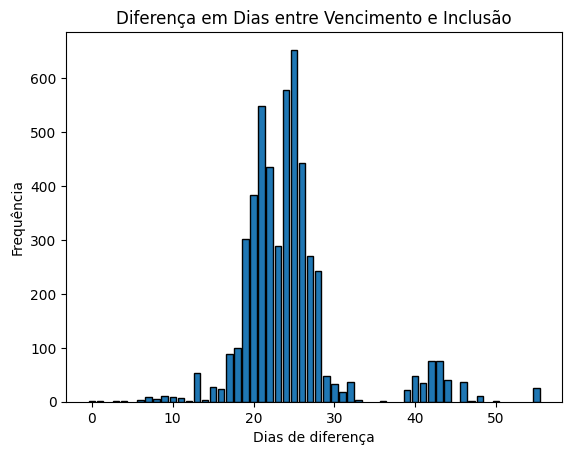

In [13]:


# Gráfico de barras
plt.bar(TipoData.index, TipoData.values, edgecolor="black")
plt.title("Diferença em Dias entre Vencimento e Inclusão")
plt.xlabel("Dias de diferença")
plt.ylabel("Frequência")
plt.show()


C:\Users\Inteli\AppData\Local\Temp\ipykernel_64004\1235095777.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  boletosPagos['vl_boleto'] = pd.to_numeric(boletosPagos['vl_boleto'], errors='coerce')


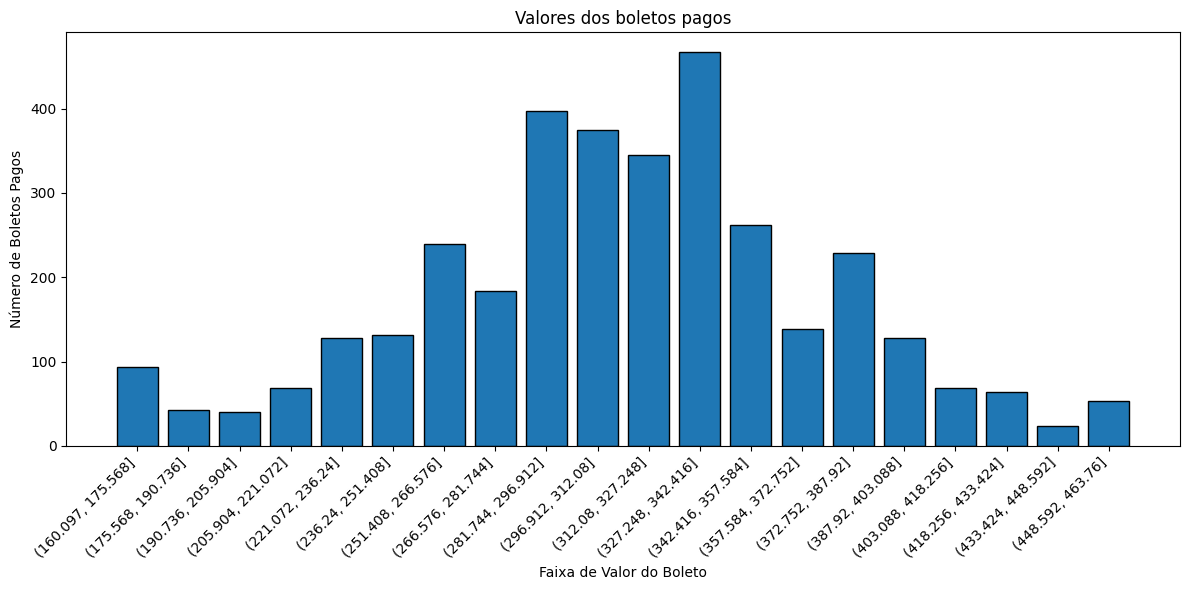

In [14]:
boletosPagos = TabelaAtual[TabelaAtual['status_num'] == 2]

boletosPagos['vl_boleto'] = pd.to_numeric(boletosPagos['vl_boleto'], errors='coerce')

# Remover linhas que ficaram NaN (eram inválidas)
boletosPagos = boletosPagos.dropna(subset=['vl_boleto'])

# Cria as faixas
bins = 20
boletosPagos['faixa_boleto'] = pd.cut(boletosPagos['vl_boleto'], bins=bins)

# Conta por faixa
vBoletoPagosGrouped = boletosPagos['faixa_boleto'].value_counts().sort_index()

# Gráfico
fig, ax = plt.subplots(figsize=(12,6))
ax.bar(vBoletoPagosGrouped.index.astype(str), vBoletoPagosGrouped.values, edgecolor="black")

ax.set_title("Valores dos boletos pagos")
ax.set_xlabel("Faixa de Valor do Boleto")
ax.set_ylabel("Número de Boletos Pagos")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

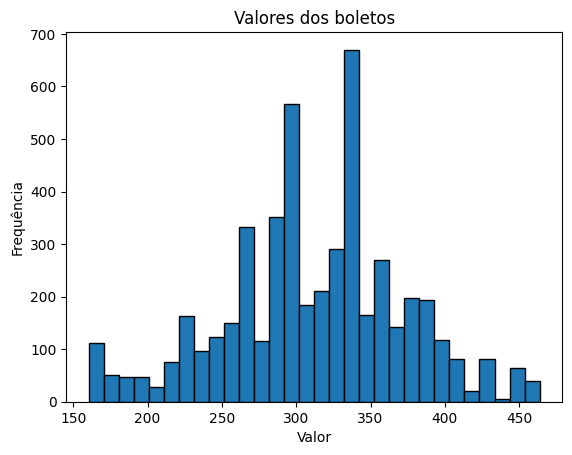

In [15]:
vBoleto = TabelaAtual['vl_boleto'].value_counts().sort_index()

plt.hist(TabelaAtual['vl_boleto'], bins=30, edgecolor="black")

plt.title("Valores dos boletos")
plt.xlabel("Valor")
plt.ylabel("Frequência")
plt.show()

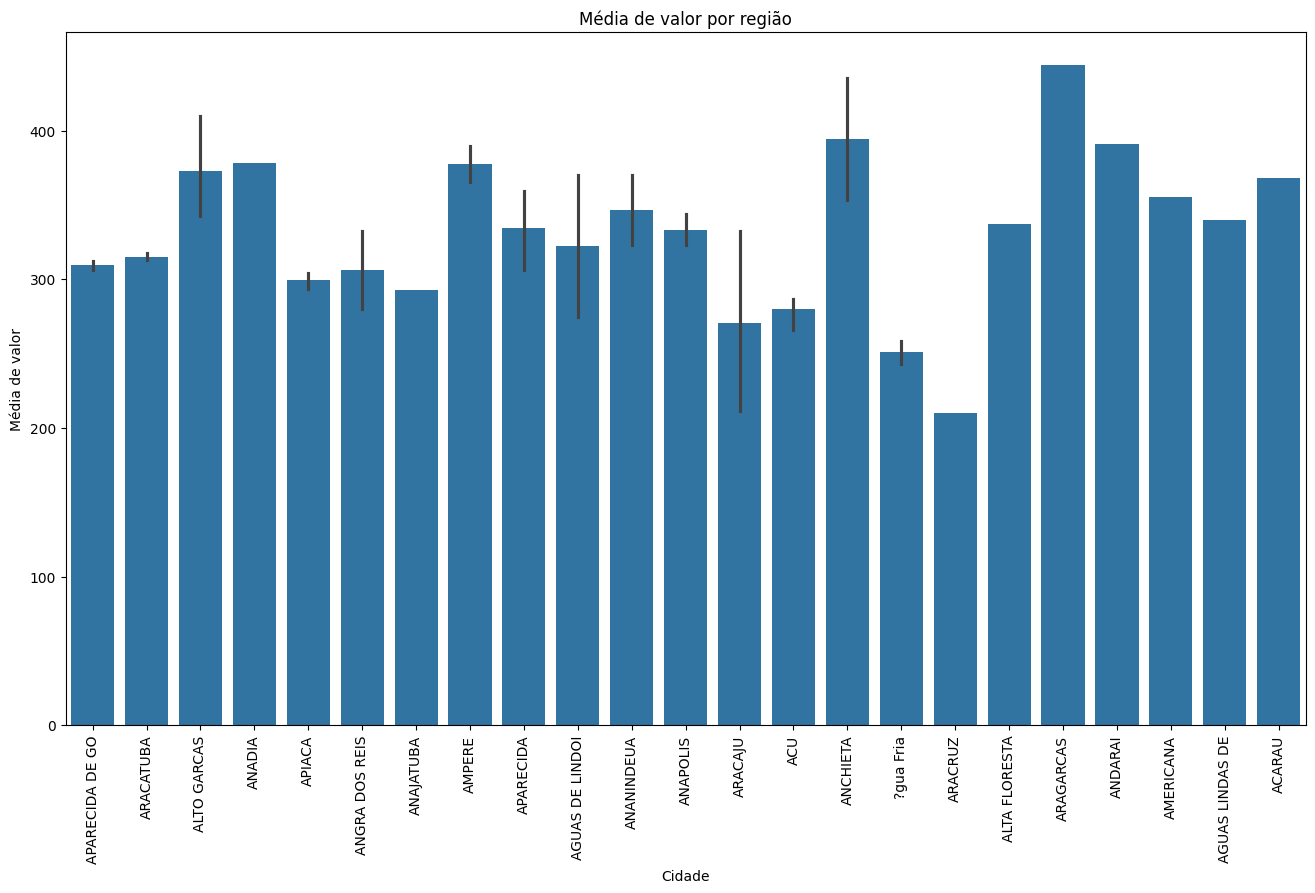

In [16]:


numeroPorCidade = TabelaAtual['pagador_cidade'].value_counts().sort_index()

plt.figure(figsize=(16,9))
sns.barplot(x="pagador_cidade", y="vl_boleto", data=TabelaAtual, estimator="mean")
plt.xticks(rotation=90)
plt.title("Média de valor por região")
plt.xlabel("Cidade")
plt.ylabel("Média de valor")
plt.show()

C:\Users\Inteli\AppData\Local\Temp\ipykernel_64004\440678695.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  boletos_incluidos = TabelaAtual.groupby('mes_inclusao').size()
C:\Users\Inteli\AppData\Local\Temp\ipykernel_64004\440678695.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  boletos_pagos = TabelaAtual[TabelaAtual['status_num'] == 2].groupby('mes_pag').size()


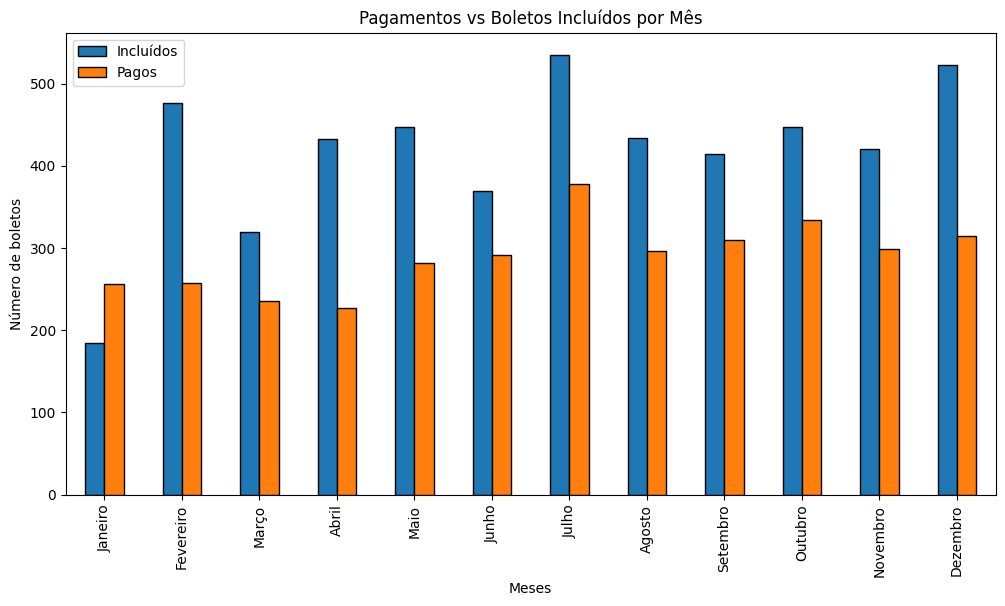

In [17]:
TabelaAtual['mes_pag'] = pd.Categorical(TabelaAtual['mes_pag'], categories=ordem_meses, ordered=True)
TabelaAtual['mes_inclusao'] = pd.Categorical(TabelaAtual['mes_inclusao'], categories=ordem_meses, ordered=True)

# Agrupamento
boletos_incluidos = TabelaAtual.groupby('mes_inclusao').size()
boletos_pagos = TabelaAtual[TabelaAtual['status_num'] == 2].groupby('mes_pag').size()

# Unir em dataframe
df_mes = pd.concat([boletos_incluidos, boletos_pagos], axis=1)
df_mes.columns = ['Incluídos', 'Pagos']
df_mes = df_mes.fillna(0)

# Taxa de pagamento
df_mes['Taxa'] = (df_mes['Pagos'] / df_mes['Incluídos']) * 100

# Gráfico
fig, ax1 = plt.subplots(figsize=(12, 6))

df_mes[['Incluídos', 'Pagos']].plot(kind='bar', ax=ax1, edgecolor="black")
ax1.set_ylabel("Número de boletos")
ax1.set_xlabel("Meses")
ax1.set_title("Pagamentos vs Boletos Incluídos por Mês")


# Legendas
ax1.legend(loc="upper left")


plt.show()

## Hipóteses

 Nesta análise, foram levantadas hipóteses relacionadas ao comportamento de pagamento de boletos pelos usuários da plataforma. O objetivo é identificar padrões e fatores que influenciam o tempo de pagamento. Essas hipóteses servem como base para exploração de dados e para a criação do modelo preditivo, auxiliando na compreensão dos fatores que impactam atrasos, pontualidade nos pagamentos e permitem identificar quais variáveis impactão ou não no pagamento de boletos.

### Hipótese 1 - Dias necessários para o pagamento de boletos

**Tese:** A maioria dos boletos, tanto pagos quanto não pagos, possui um intervalo entre a data de inclusão e a data de vencimento concentrado entre 20 e 30 dias.

**Resultado:** Positivo, ambos possuem um intervalo concentrado entre 20 e 30 dias.

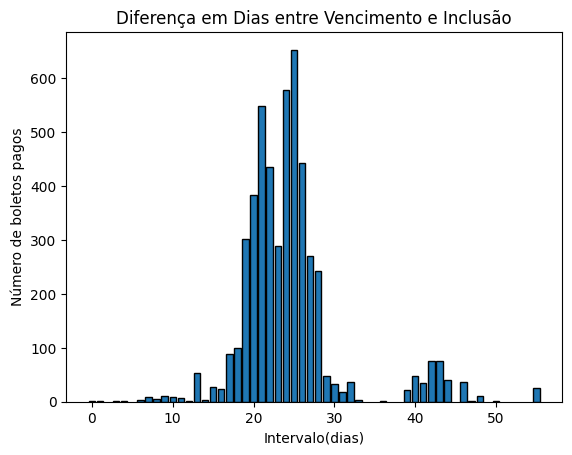

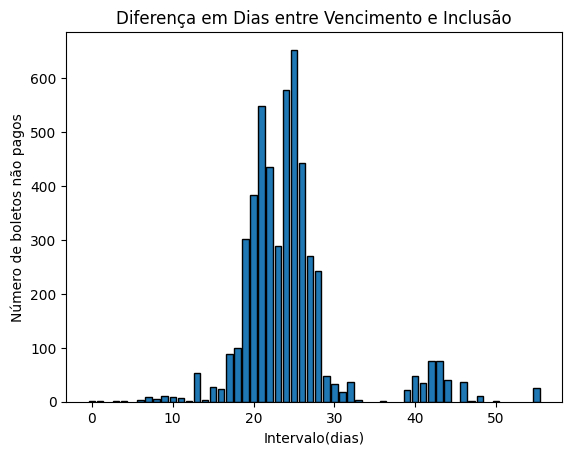

In [18]:


# Gráfico de barras - Boletos Pagos
plt.bar(TipoData.index, TipoData.values, edgecolor="black")
plt.title("Diferença em Dias entre Vencimento e Inclusão")
plt.xlabel("Intervalo(dias)")
plt.ylabel("Número de boletos pagos")
plt.show()

# Gráfico de barras - Boletos Não Pagos
plt.bar(TipoData.index, TipoData.values, edgecolor="black")
plt.title("Diferença em Dias entre Vencimento e Inclusão")
plt.xlabel("Intervalo(dias)")
plt.ylabel("Número de boletos não pagos")
plt.show()

### Hipótese 2 -  O período do ano influencia diretamente na taxa de pagamento de boletos.

&nbsp;&nbsp;&nbsp;&nbsp; Esta hipótese busca confirmar que a taxa de pagamento de boletos varia de acordo com o mês ou período do ano, influenciada por fatores sazonais e econômicos. Em determinados meses, como dezembro (festividades de fim de ano) ou março/abril (pagamento de impostos), pode haver uma maior pressão financeira, reduzindo a taxa de quitação de boletos. Já em períodos de maior liquidez, como meses de recebimento de 13º salário ou distribuição de bônus corporativos, a taxa de pagamento tende a aumentar. Além disso, mudanças na governança ou estratégias financeiras das empresas ao longo do ano podem impactar diretamente a capacidade de honrar pagamentos.

&nbsp;&nbsp;&nbsp;&nbsp; No gráfico abaixo, análisamos mais de 30 mil boletos entre um período de 12 meses, utilizando Python e bibliotecas como Pandas, Matplotlib e Seaborn. O eixo X representa os meses do ano, enquanto o Y representa o número de boletos. A barra em azul representa os boletos incluídos, a laranja os boletos pagos e a linha vermelha representa a taxa de pagamento em porcentagem.


C:\Users\Inteli\AppData\Local\Temp\ipykernel_64004\1060069100.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  boletos_incluidos = TabelaAtual.groupby('mes_inclusao').size()
C:\Users\Inteli\AppData\Local\Temp\ipykernel_64004\1060069100.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  boletos_pagos = TabelaAtual[TabelaAtual['status_num'] == 2].groupby('mes_pag').size()


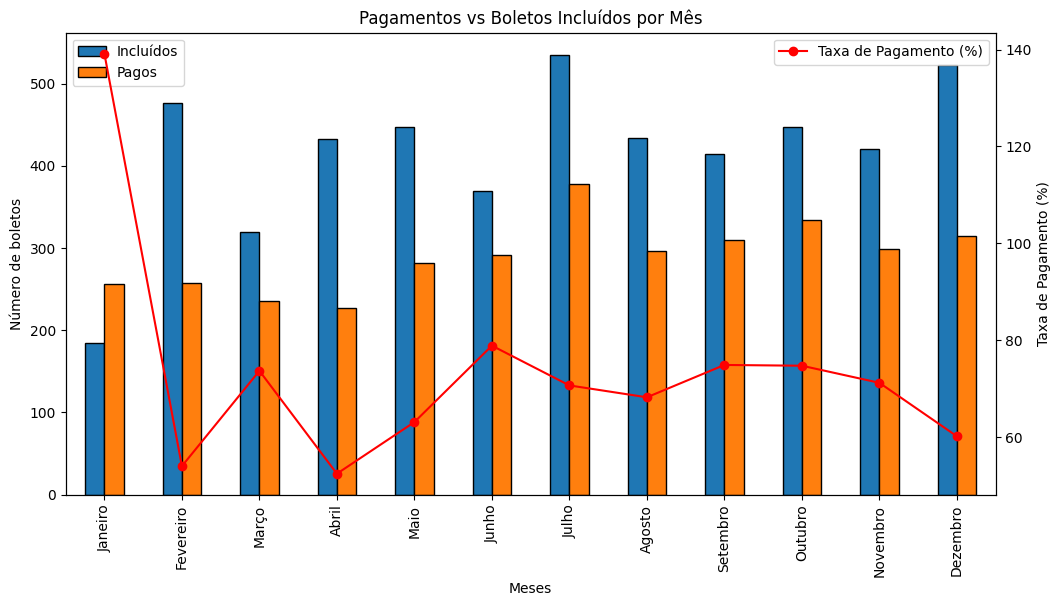

In [19]:


TabelaAtual['mes_pag'] = pd.Categorical(TabelaAtual['mes_pag'], categories=ordem_meses, ordered=True)
TabelaAtual['mes_inclusao'] = pd.Categorical(TabelaAtual['mes_inclusao'], categories=ordem_meses, ordered=True)

# Agrupamento
boletos_incluidos = TabelaAtual.groupby('mes_inclusao').size()
boletos_pagos = TabelaAtual[TabelaAtual['status_num'] == 2].groupby('mes_pag').size()

# Unir em dataframe
df_mes = pd.concat([boletos_incluidos, boletos_pagos], axis=1)
df_mes.columns = ['Incluídos', 'Pagos']
df_mes = df_mes.fillna(0)

# Taxa de pagamento
df_mes['Taxa'] = (df_mes['Pagos'] / df_mes['Incluídos']) * 100

# Gráfico
fig, ax1 = plt.subplots(figsize=(12, 6))

df_mes[['Incluídos', 'Pagos']].plot(kind='bar', ax=ax1, edgecolor="black")
ax1.set_ylabel("Número de boletos")
ax1.set_xlabel("Meses")
ax1.set_title("Pagamentos vs Boletos Incluídos por Mês")

# Eixo secundário
ax2 = ax1.twinx()
ax2.plot(df_mes.index, df_mes['Taxa'], color="red", marker="o", label="Taxa de Pagamento (%)")
ax2.set_ylabel("Taxa de Pagamento (%)")

# Legendas
ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

plt.show()

    

&nbsp;&nbsp;&nbsp;&nbsp; A análise do gráfico revela padrões importantes no comportamento de pagamento dos boletos. Em janeiro, observa-se que a quantidade de pagamentos supera a de inclusões, o que desmonstra o impacto das festividades e despesas concentradas no fim do ano. Isso ocorre porque em dezembro há um aumento expressivo na emissão de boletos, enquanto em janeiro, período de retomada das atividades, o número de novos boletos é significativamente menor.

&nbsp;&nbsp;&nbsp;&nbsp; Além disso, nota-se que em abril a taxa de pagamentos apresenta um dos menores índices do ano, o que pode estar associado à sobrecarga financeira causada pelo pagamento de impostos obrigatórios, como o Imposto de Renda e tributos anuais. Esse padrão reforça a influência de fatores econômicos e sazonais na dinâmica de pagamento.

**Resultado:** Portanto, é possível afirmar que o período do ano influncia diretamente no pagamento de boletos.

### Hipótese 3 - O tempo necessário para pagamento de boletos varia de acordo com o perfil financeiro e comportamento dos clientes

&nbsp;&nbsp;&nbsp;&nbsp; Esta hipótese busca confirmar que o tempo necessário para pagamento de boletos varia de acordo com o perfil financeiro e comportamento dos clientes. Observa-se que grande parte dos boletos é quitada dentro dos primeiros 30 dias após a inclusão, indicando que muitos clientes priorizam pagamentos imediatos. Por outro lado, uma parcela menor apresenta atrasos mais longos, podendo estar relacionada a dificuldades financeiras temporárias, menor disciplina de pagamento ou atrasos na compensação bancária.

&nbsp;&nbsp;&nbsp;&nbsp; No gráfico abaixo, o eixo X representa os dias necessários para pagar, enquanto o eixo Y representa o número de boletos quitados em cada período. Cada ponto azul indica a quantidade de boletos pagos após determinado número de dias desde a inclusão.

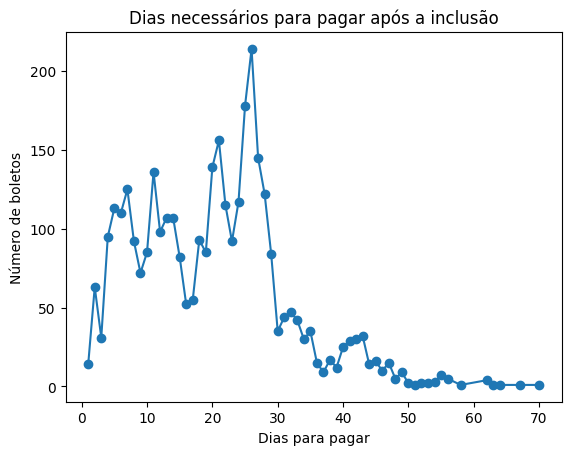

In [20]:

    # Gráfico de barras
plt.plot(DiasParaPagar.index, DiasParaPagar.values, marker="o")
plt.title("Dias necessários para pagar após a inclusão")
plt.xlabel("Dias para pagar")
plt.ylabel("Número de boletos")
plt.show()


&nbsp;&nbsp;&nbsp;&nbsp; A análise do gráfico revela padrões importantes no comportamento de pagamento. Observa-se um pico significativo entre 20 e 30 dias, sugerindo que a maioria dos clientes paga dentro do prazo mensal típico. Além disso, o número de boletos pagos decresce rapidamente após 40 dias, evidenciando que atrasos prolongados são menos frequentes, mas ainda presentes, indicando a necessidade de monitoramento e estratégias de cobrança para evitar inadimplência.

&nbsp;&nbsp;&nbsp;&nbsp; **Resultado:** Portanto, é possível afirmar que o tempo de pagamento de boletos segue um padrão concentrado nos primeiros 30 dias, com uma diminuição acentuada à medida que os dias avançam.

### Hipótese 4 - Boletos com valores mais altos tendem a ser pagos em um maior número de dias após a emissão, enquanto boletos de menor valor costumam ser liquidados mais rapidamente.

&nbsp;&nbsp;&nbsp;&nbsp; Essa hipótese busca afirmar se valores elevados representam um maior impacto no orçamento do cliente, já que exigem maior planejamento financeiro, o que pode gerar atrasos ou maior tempo médio até o pagamento.

&nbsp;&nbsp;&nbsp;&nbsp; Esse comportamento pode estar associado tanto ao poder aquisitivo dos clientes quanto à priorização de despesas no ciclo financeiro. 

&nbsp;&nbsp;&nbsp;&nbsp; No gráfico abaixo, o eixo X representa os dias necessários para pagar o boleto e o Y o valor do boleto.

C:\Users\Inteli\AppData\Local\Temp\ipykernel_64004\3912009524.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DiasParaPagar['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')


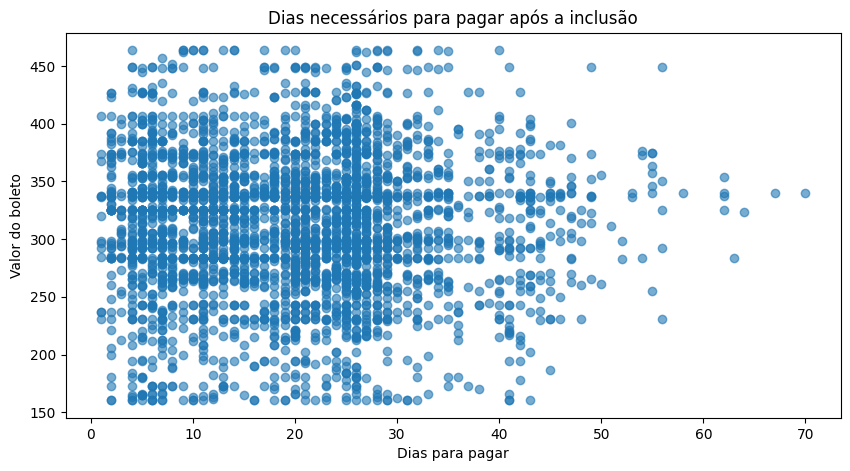

In [21]:
DiasParaPagar = TabelaAtual[TabelaAtual['dias_para_pagar'] > 0] 
DiasParaPagar['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')
plt.figure(figsize=(10,5)) 
plt.scatter(DiasParaPagar['dias_para_pagar'], DiasParaPagar['vl_boleto'], alpha=0.6, marker="o") 
plt.title("Dias necessários para pagar após a inclusão") 
plt.xlabel("Dias para pagar") 
plt.ylabel("Valor do boleto") 
plt.show()

&nbsp;&nbsp;&nbsp;&nbsp; A partir da análise do gráfico acima, é possível identificar que não há uma tendência linear clara entre essas variáveis. A maioria dos pagamentos ocorre em até 30 dias, concentrando-se em boletos de R$ 200 a R$ 400. Casos isolados de valores acima de R$ 450 mostram pagamentos tanto rápidos quanto atrasados, sugerindo que o valor sozinho não determina o tempo de quitação. Após 40 dias, os pagamentos se tornam mais raros. Assim, o prazo para pagamento parece depender mais de fatores como comportamento do cliente, sazonalidade ou disciplina financeira, indicando que o valor do boleto deve ser analisado junto a outras variáveis em modelos preditivos.

**Resultado:** Portanto, é possível afirmar que NÃO há uma relação clara entre o valor do boleto e tempo necessário para pagar.


### Hipótese 5 - A média de acesso de pessoas que pagaram o boleto é maior que as que não pagaram.

&nbsp;&nbsp;&nbsp;&nbsp; Essa hipótese busca confirmar que usuários que efetivam o pagamento de seus boletos tendem a apresentar uma quantidade de acessos à plataforma significativamente maior do que aqueles que não realizam o pagamento.

&nbsp;&nbsp;&nbsp;&nbsp; O número de acessos pode refletir o nível de engajamento do usuário com a plataforma. Um usuário mais engajado costuma ter maior contato com os serviços, maior percepção de valor e, consequentemente, maior probabilidade de honrar o pagamento. Por outro lado, usuários com baixa frequência de acessos podem demonstrar desinteresse ou menor vínculo, aumentando a chance de inadimplência.

&nbsp;&nbsp;&nbsp;&nbsp; Se a hipótese for confirmada, a quantidade de acesso pode se tornar uma forte variável na implementação do modelo preditivo, pois se torna um dos indicadores de pagamento e influencia na busca de inadimplentes.

&nbsp;&nbsp;&nbsp;&nbsp; No gráfico abaixo, o eixo X possui dois valores, os boletos pagos e não pagos, enquanto o eixo Y representa a média de acessos dos usuários de cada um desses grupos.

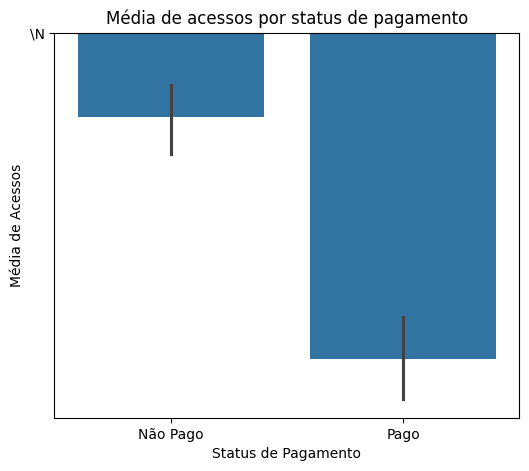

In [22]:
plt.figure(figsize=(6,5))
sns.barplot(x="pago/n", y="qtd_acessos_pagador", data=TabelaAtual, estimator="mean")

plt.title("Média de acessos por status de pagamento")
plt.xlabel("Status de Pagamento")
plt.ylabel("Média de Acessos")
plt.show()


**Resultado:** Portanto, através da análise do gráfico, é possível confirmar que a média de acessos das pessoas que pagaram os boletos é consideravelmente maior que das pessoas que não pagaram.

### Hipótese 6 - Média de valor entre boletos pagos e não pagos

&nbsp;&nbsp;&nbsp;&nbsp; Esta hipótese busca afirmar que a média de valor é maior para os boletos com status 'Não Pago', sugerindo que valores mais altos podem influenciar negativamente a quitação dos boletos.

C:\Users\Inteli\AppData\Local\Temp\ipykernel_64004\3570382528.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DiasParaPagar['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')


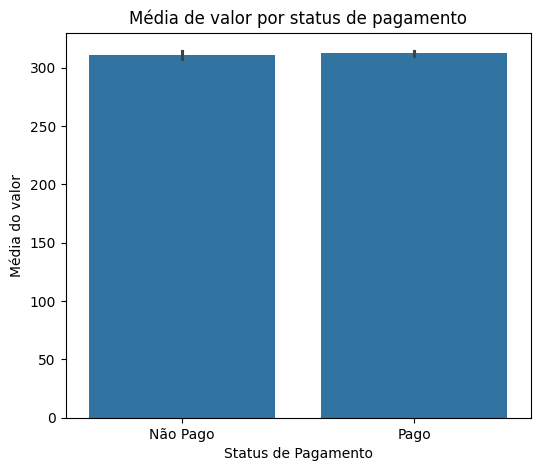

In [23]:

mapping = {0: 'Não Pago', 1: 'Não Pago', 2: 'Pago'}
TabelaAtual['pago/n'] = TabelaAtual['status_num'].map(mapping)

TabelaAtual['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')
DiasParaPagar['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')
plt.figure(figsize=(6,5))
sns.barplot(x="pago/n", y="vl_boleto", data=TabelaAtual, estimator="mean")

plt.title("Média de valor por status de pagamento")
plt.xlabel("Status de Pagamento")
plt.ylabel("Média do valor")
plt.show()

**Resultado**: Após a análise do gráfico, pode-se concluir que a média de valor entre boletos pagos e não pagos é praticamente igual, o que anula completamente a hipótese de que a média de valor de boletos não pagos é maior.


&nbsp;&nbsp;&nbsp;&nbsp; As hipóteses levantadas permitem direcionar análises quantitativas para verificar a influência de diferentes fatores sobre o comportamento de pagamento. A avaliação de padrões relacionados a valores, frequência de acessos e histórico de pagamentos ajuda a confirmar ou rejeitar essas hipóteses, identificando as variáveis relevantes para a criação do nosso modelo preditivo destinado a Finnet.
